# TP2 - Visión por Computadora I

Especialización en Inteligencia Artificial (CEIA), FIUBA.

**Integrantes**

- Hernando Alexis Gonzalez
- Victoria Villalba Teves
- Silvert Kevin Quispe Pacompia

**Consigna**
Implementar un detector de máximo enfoque sobre un video aplicando técnicas de análisis espectral similar al que utilizan las cámaras digitales modernas. El video a procesar será: “focus_video.mov”.
1. Se debe implementar un algoritmo que dada una imagen, o región, calcule la métrica propuesta en el paper "Image Sharpness Measure for Blurred Images in Frequency Domain“ y realizar dos experimentos:

    1. Medición sobre todo el frame
    2. Medición sobre una ROI ubicada en el centro del frame. Area de la ROI = 5 o 10% del area total del frame.
    
Para cada experimento se debe presentar:

- Una curva o varias curvas que muestren la evolución de la métrica frame a frame donde se vea claramente cuando el algoritmo detecto la  región de máximo enfoque.

El algoritmo de detección a implementar debe detectar y devolver los puntos de máximo enfoque de manera automática.

**Puntos extra:** aplicar *unsharp masking* para expandir la zona de enfoque y recalcular la métrica.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np


In [2]:
# Video provisto por la catedra en Material_TPs/TP2.
DATA_DIR = Path("Data")
VIDEO_PATH = DATA_DIR / "focus_video.mov"

if not VIDEO_PATH.is_file():
    raise FileNotFoundError(f"No se encontro el video: {VIDEO_PATH.resolve()}")

## Métrica de enfoque en el dominio de la frecuencia

Siguiendo el algoritmo del artículo *Image Sharpness Measure for Blurred Images in Frequency Domain* (De y Masilamani, 2013, secciones 3.1–3.2), calculamos la FFT 2D centrada y su magnitud. Se cuentan los coeficientes cuya magnitud supera `max(magnitud) / 1000`; la métrica `FM` es ese conteo dividido por el número total de píxeles. En general, una imagen más enfocada tiene más componentes de alta frecuencia y un `FM` mayor.

Se mide cada frame completo y una ROI central que ocupa aproximadamente el 10% del área del frame.

In [3]:
def frequency_domain_focus_measure(image):
    """Calcula FM según De y Masilamani sobre una imagen gris o BGR."""
    if image.ndim == 3:
        image = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    if image.ndim != 2 or image.size == 0:
        raise ValueError("La entrada debe ser una imagen no vacía, gris o BGR.")

    spectrum = np.fft.fftshift(np.fft.fft2(image.astype(np.float64)))
    magnitude = np.abs(spectrum)
    threshold = magnitude.max() / 1000.0
    return float(np.count_nonzero(magnitude > threshold) / magnitude.size)


def centered_roi_bounds(frame_shape, area_fraction=0.10):
    """Devuelve los límites x0, y0, x1, y1 de una ROI central."""
    if not 0 < area_fraction < 1:
        raise ValueError("area_fraction debe estar entre 0 y 1.")

    height, width = frame_shape[:2]
    scale = np.sqrt(area_fraction)
    roi_width = max(1, int(round(width * scale)))
    roi_height = max(1, int(round(height * scale)))
    x0 = (width - roi_width) // 2
    y0 = (height - roi_height) // 2
    return x0, y0, x0 + roi_width, y0 + roi_height


ROI_AREA_FRACTION = 0.10
capture = cv.VideoCapture(str(VIDEO_PATH))
if not capture.isOpened():
    raise RuntimeError(f"No se pudo abrir el video: {VIDEO_PATH.resolve()}")

fps = capture.get(cv.CAP_PROP_FPS)
if fps <= 0:
    capture.release()
    raise RuntimeError("El video no informa una tasa de cuadros (FPS) válida.")

frame_indices = []
gray_frames = []
full_frame_scores = []
roi_scores = []
frame_index = 0
roi_bounds = None
frame_shape = None

try:
    while True:
        success, frame = capture.read()
        if not success:
            break

        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        if roi_bounds is None:
            frame_shape = gray.shape
            roi_bounds = centered_roi_bounds(frame_shape, ROI_AREA_FRACTION)

        x0, y0, x1, y1 = roi_bounds
        gray_frames.append(gray)
        frame_indices.append(frame_index)
        full_frame_scores.append(frequency_domain_focus_measure(gray))
        roi_scores.append(frequency_domain_focus_measure(gray[y0:y1, x0:x1]))
        frame_index += 1

finally:
    capture.release()

if not frame_indices:
    raise RuntimeError(f"No se pudo leer ningún frame de {VIDEO_PATH.resolve()}.")

frame_indices = np.asarray(frame_indices)
frame_times = frame_indices / fps
full_frame_scores = np.asarray(full_frame_scores)
roi_scores = np.asarray(roi_scores)

x0, y0, x1, y1 = roi_bounds
actual_roi_area = (x1 - x0) * (y1 - y0) / (frame_shape[0] * frame_shape[1])
print(f"Frames procesados: {len(frame_indices)}")
print(f"Resolución: {frame_shape[1]} x {frame_shape[0]} px | FPS: {fps:.3f}")
print(f"ROI central: {x1 - x0} x {y1 - y0} px ({actual_roi_area:.2%} del frame)")

Frames procesados: 171
Resolución: 640 x 360 px | FPS: 29.970
ROI central: 202 x 114 px (9.99% del frame)


## Detección automática del máximo enfoque

Para cada experimento el algoritmo devuelve automáticamente:

- **Punto de máximo enfoque:** el frame que maximiza `FM`.
- **Región de máximo enfoque:** el tramo continuo de frames alrededor del máximo cuyo `FM` es al menos el 90% del máximo (`FOCUS_REGION_RATIO`). La región se sombrea en verde sobre la curva.

El número de frame que se informa comienza en 1.

Frame completo: frame 110, t = 3.637 s, FM = 0.028624 | región: frames 80–116 (2.636–3.837 s, 37 frames)
ROI central: frame 112, t = 3.704 s, FM = 0.359389 | región: frames 106–114 (3.504–3.770 s, 9 frames)


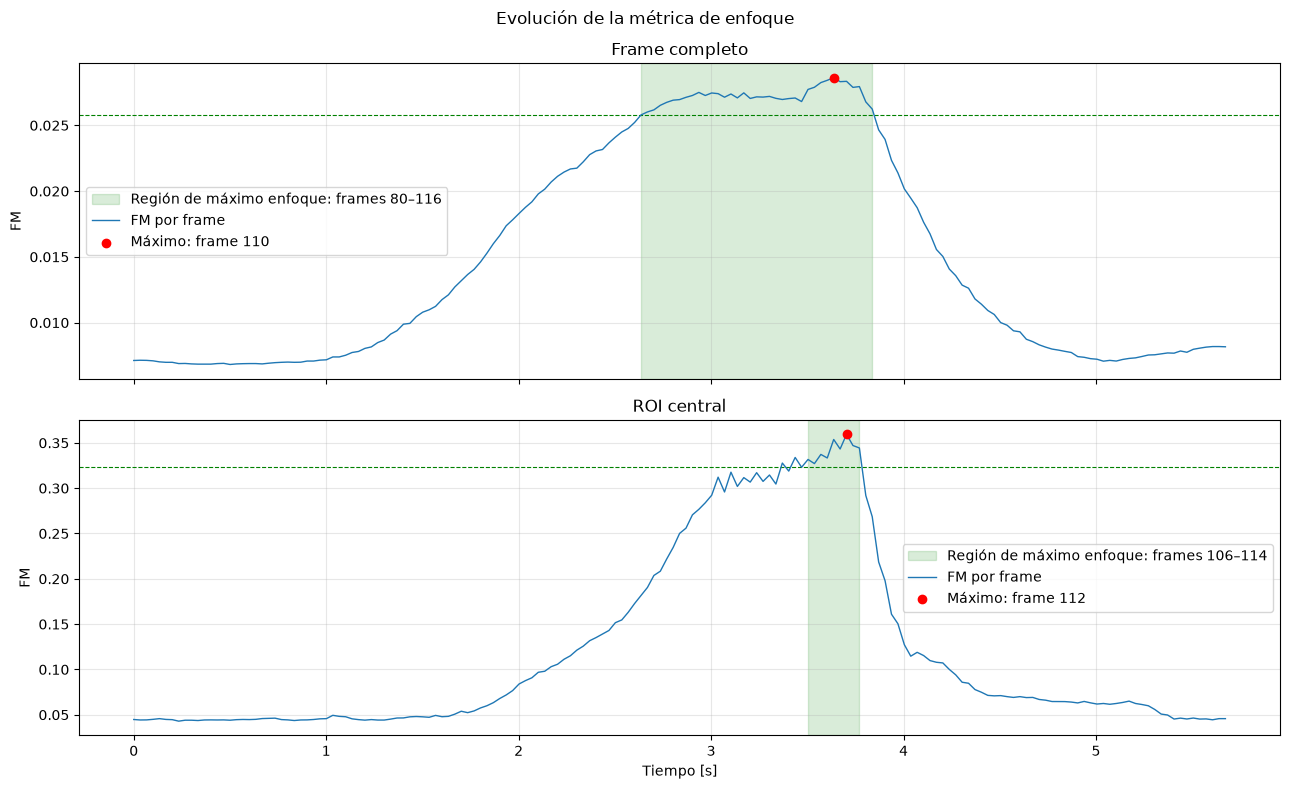

In [4]:
FOCUS_REGION_RATIO = 0.90


def detect_focus(scores, threshold):
    """Devuelve el índice del máximo y el tramo continuo [inicio, fin] con FM >= threshold que lo contiene."""
    peak = int(np.argmax(scores))
    start = peak
    while start > 0 and scores[start - 1] >= threshold:
        start -= 1
    end = peak
    while end < len(scores) - 1 and scores[end + 1] >= threshold:
        end += 1
    return peak, start, end


score_curves = {
    "Frame completo": full_frame_scores,
    "ROI central": roi_scores,
}
focus_maxima = {}

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, (label, scores) in zip(axes, score_curves.items()):
    threshold = FOCUS_REGION_RATIO * scores.max()
    peak_index, start, end = detect_focus(scores, threshold)
    maximum = {
        "frame": int(frame_indices[peak_index]) + 1,
        "time_seconds": float(frame_times[peak_index]),
        "FM": float(scores[peak_index]),
        "threshold": float(threshold),
        "region_frames": (int(frame_indices[start]) + 1, int(frame_indices[end]) + 1),
        "region_seconds": (float(frame_times[start]), float(frame_times[end])),
    }
    focus_maxima[label] = maximum

    ax.axvspan(
        *maximum["region_seconds"],
        color="green",
        alpha=0.15,
        label=f"Región de máximo enfoque: frames {start + 1}–{end + 1}",
    )
    ax.axhline(threshold, color="green", linestyle="--", linewidth=0.8)
    ax.plot(frame_times, scores, linewidth=1, label="FM por frame")
    ax.scatter(
        maximum["time_seconds"],
        maximum["FM"],
        color="red",
        zorder=3,
        label=f"Máximo: frame {maximum['frame']}",
    )
    ax.set_title(label)
    ax.set_ylabel("FM")
    ax.grid(True, alpha=0.3)
    ax.legend()
    print(
        f"{label}: frame {maximum['frame']}, "
        f"t = {maximum['time_seconds']:.3f} s, FM = {maximum['FM']:.6f} | "
        f"región: frames {start + 1}–{end + 1} "
        f"({maximum['region_seconds'][0]:.3f}–{maximum['region_seconds'][1]:.3f} s, "
        f"{end - start + 1} frames)"
    )

axes[-1].set_xlabel("Tiempo [s]")
fig.suptitle("Evolución de la métrica de enfoque")
fig.tight_layout()
plt.show()

## Análisis de resultados

Se procesaron 171 frames de un video de 640 × 360 píxeles a 29,97 FPS. La región central utilizada mide 202 × 114 píxeles y representa aproximadamente el 10% del área del frame, de acuerdo con la consigna.

En el experimento sobre el frame completo, la métrica FM alcanza su máximo en el frame 110, a los 3,637 s, con un valor de 0,028624. Para la ROI central, el máximo se detecta en el frame 112, a los 3,704 s, con un valor de 0,359389. La diferencia entre ambos máximos es de dos frames, aproximadamente 0,067 s; por lo tanto, las dos mediciones señalan una zona temporal de máximo enfoque muy similar.

Tomando como región de máximo enfoque el tramo continuo con `FM` ≥ 90% del máximo, el frame completo devuelve los frames 80–116 (2,636–3,837 s, 37 frames) y la ROI central los frames 106–114 (3,504–3,770 s, 9 frames). La región de la ROI está contenida en la del frame completo y es mucho más angosta: la curva de la ROI tiene un pico más marcado, mientras que la del frame completo forma una meseta porque promedia zonas de la escena que están a distintas profundidades y entran en foco en momentos distintos.

En ambas curvas la métrica aumenta durante la primera parte del video, alcanza sus valores más altos aproximadamente entre los 3 y 3,8 s y luego desciende con rapidez. La curva del frame completo es más suave, mientras que la de la ROI presenta mayores fluctuaciones. Esto es compatible con que la medición global agregue información de distintas zonas de la escena, mientras que la ROI responde a los detalles locales del área central. A pesar de esa diferencia, ambas curvas coinciden en la ubicación temporal del máximo.

Los valores FM de ambas curvas no deben compararse directamente como si uno indicara cuánto más enfocada está una región que la otra: se calcularon sobre imágenes de distinto tamaño y contenido, con espectros de frecuencias diferentes. Para contrastar los experimentos resulta más informativo comparar el momento del máximo y la forma general de las curvas.

La detección automática selecciona el frame con el mayor FM observado en cada experimento y la región continua de frames cercanos a ese máximo. Este resultado identifica el máximo relativo dentro del video analizado; no constituye por sí solo una medida absoluta del enfoque óptico, ya que la métrica también puede verse afectada por la textura de la escena, el ruido y los cambios de iluminación.

## Puntos extra: *unsharp masking*

El *unsharp masking* realza los detalles finos sumándole a la imagen la diferencia entre ella y una versión suavizada:

$$I_{\text{sharp}} = I + a\,(I - G_\sigma * I) = (1 + a)\,I - a\,(G_\sigma * I)$$

donde $G_\sigma$ es un filtro gaussiano y $a$ controla la intensidad del realce. Al reforzar las altas frecuencias, frames que estaban levemente desenfocados alcanzan valores de `FM` cercanos a los del frame mejor enfocado, por lo que la zona de enfoque se expande.

Para medir esa expansión, se aplica el filtro a todos los frames, se recalcula `FM` en ambos experimentos y se cuenta cuántos frames superan **el mismo umbral** usado antes (90% del máximo de la curva original).

Frame completo: máximo en frame 112 (FM = 0.057990) | región: frames 62–123 (62 frames) vs. original 80–116 (37 frames)
ROI central: máximo en frame 112 (FM = 0.570349) | región: frames 83–117 (35 frames) vs. original 106–114 (9 frames)


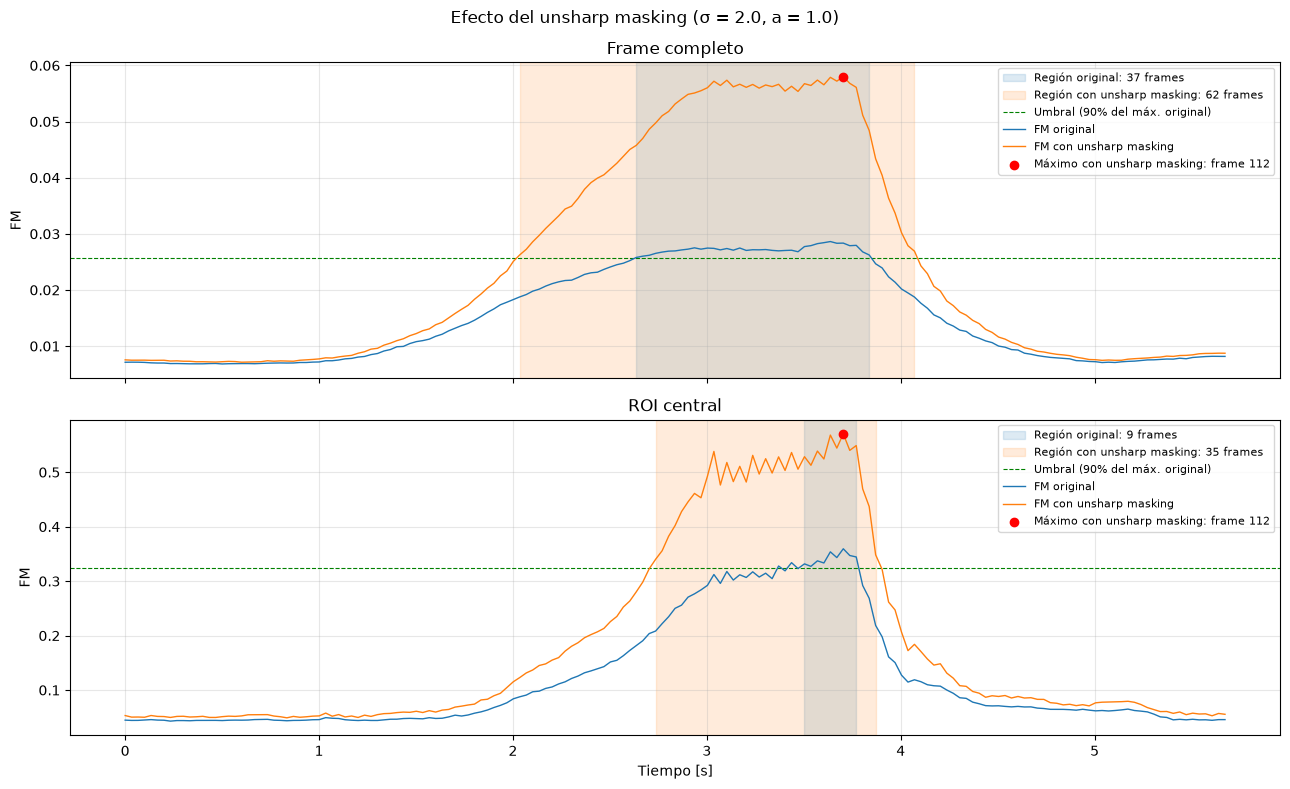

In [5]:
USM_SIGMA = 2.0
USM_AMOUNT = 1.0


def unsharp_mask(image, sigma=USM_SIGMA, amount=USM_AMOUNT):
    """Aplica unsharp masking: (1 + amount) * I - amount * G_sigma(I)."""
    blurred = cv.GaussianBlur(image, (0, 0), sigma)
    return cv.addWeighted(image, 1.0 + amount, blurred, -amount, 0)


x0, y0, x1, y1 = roi_bounds
sharpened_frames = [unsharp_mask(gray) for gray in gray_frames]
sharpened_curves = {
    "Frame completo": np.asarray([frequency_domain_focus_measure(g) for g in sharpened_frames]),
    "ROI central": np.asarray([frequency_domain_focus_measure(g[y0:y1, x0:x1]) for g in sharpened_frames]),
}

focus_maxima_usm = {}
fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for ax, label in zip(axes, score_curves):
    original = score_curves[label]
    sharpened = sharpened_curves[label]
    threshold = focus_maxima[label]["threshold"]  # mismo umbral que la curva original
    peak_index, start, end = detect_focus(sharpened, threshold)
    original_start, original_end = (f - 1 for f in focus_maxima[label]["region_frames"])
    focus_maxima_usm[label] = {
        "frame": int(frame_indices[peak_index]) + 1,
        "FM": float(sharpened[peak_index]),
        "region_frames": (int(frame_indices[start]) + 1, int(frame_indices[end]) + 1),
    }

    ax.axvspan(frame_times[original_start], frame_times[original_end], color="tab:blue", alpha=0.15,
               label=f"Región original: {original_end - original_start + 1} frames")
    ax.axvspan(frame_times[start], frame_times[end], color="tab:orange", alpha=0.15,
               label=f"Región con unsharp masking: {end - start + 1} frames")
    ax.axhline(threshold, color="green", linestyle="--", linewidth=0.8, label="Umbral (90% del máx. original)")
    ax.plot(frame_times, original, linewidth=1, color="tab:blue", label="FM original")
    ax.plot(frame_times, sharpened, linewidth=1, color="tab:orange", label="FM con unsharp masking")
    ax.scatter(frame_times[peak_index], sharpened[peak_index], color="red", zorder=3,
               label=f"Máximo con unsharp masking: frame {peak_index + 1}")
    ax.set_title(label)
    ax.set_ylabel("FM")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    print(
        f"{label}: máximo en frame {peak_index + 1} (FM = {sharpened[peak_index]:.6f}) | "
        f"región: frames {start + 1}–{end + 1} ({end - start + 1} frames) "
        f"vs. original {original_start + 1}–{original_end + 1} ({original_end - original_start + 1} frames)"
    )

axes[-1].set_xlabel("Tiempo [s]")
fig.suptitle(f"Efecto del unsharp masking (σ = {USM_SIGMA}, a = {USM_AMOUNT})")
fig.tight_layout()
plt.show()

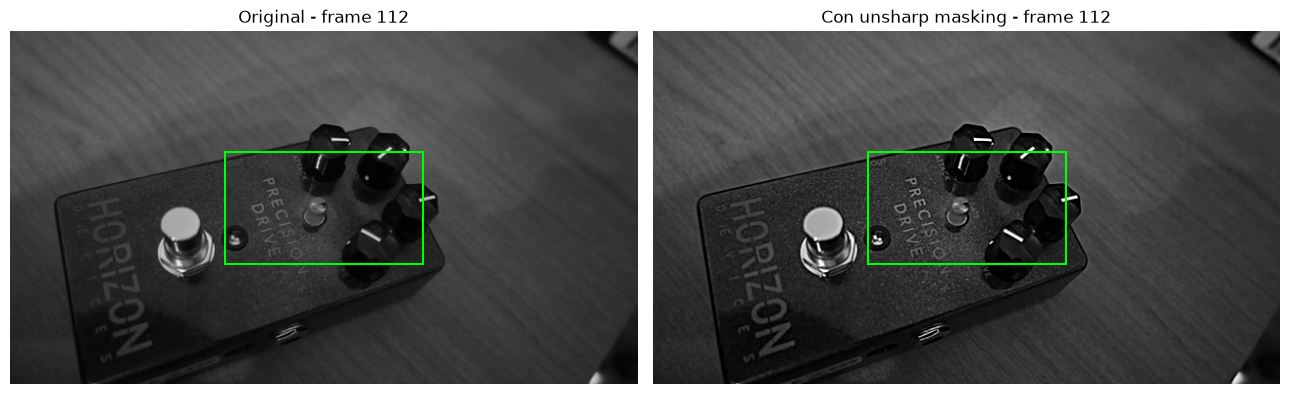

In [6]:
# Comparación visual sobre el frame de máximo enfoque de la ROI
peak = focus_maxima["ROI central"]["frame"] - 1
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, image, title in zip(
    axes,
    (gray_frames[peak], sharpened_frames[peak]),
    ("Original", "Con unsharp masking"),
):
    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", linewidth=1.5))
    ax.set_title(f"{title} - frame {peak + 1}")
    ax.axis("off")
fig.tight_layout()
plt.show()

### Análisis de los puntos extra

Con *unsharp masking* (σ = 2, a = 1) la métrica `FM` aumenta en todos los frames, y sobre todo en los que ya estaban cerca del foco, porque el filtro refuerza justamente las altas frecuencias que cuenta la métrica. Usando el mismo umbral que en la curva original (90% de su máximo):

| Experimento | Región original | Región con *unsharp masking* | Frame máximo (original → filtrado) |
|---|---|---|---|
| Frame completo | frames 80–116 (37 frames) | frames 62–123 (62 frames) | 110 → 112 |
| ROI central | frames 106–114 (9 frames) | frames 83–117 (35 frames) | 112 → 112 |

La zona de enfoque se expande en ambos experimentos: 1,7 veces en el frame completo y casi 4 veces en la ROI. La posición del máximo prácticamente no cambia, así que el filtro no altera cuál es el frame mejor enfocado; lo que hace es que más frames vecinos alcancen un nivel de detalle comparable.

Esta expansión es un efecto del realce digital y no una mejora óptica real: el *unsharp masking* no recupera información perdida por el desenfoque, solo amplifica bordes y texturas que todavía están presentes (y también el ruido). Por eso, si se usa para decidir el foco, conviene detectar el máximo sobre la imagen original y reservar el realce para mejorar la imagen final.